In [1]:
import os
import torch
import random
import numpy as np

# --- CONFIGURATION & HYPERPARAMETERS ---
CONFIG = {
    # Dataset path on Kaggle (adjust if your dataset directory name differs)
    "data_root": "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23" , # Or your specific FF++ C23 directory path

    "seed": 42,
    
    # Dataset Slicing Control (Number of total videos to use: Real + Fake combined)
    # Set to e.g., 500 or 1000 for quick debugging, or None to use the full available set.
    "max_videos_to_use": None, 
    
    # Video Temporal Properties
    "seq_len": 16,            # Number of consecutive frames sampled per video
    "img_size": 224,          # Spatial resolution for EfficientNet-B1
    
    # Training Hyperparameters
    "batch_size": 8,          # Batch size (adjust based on Kaggle GPU VRAM: T4/P100)
    "num_epochs": 5,          # Number of training epochs
    "lr": 1e-4,               # Learning rate for AdamW optimizer
    "dropout": 0.1,
    "test_split": 0.15,       # Fraction of dataset reserved for test
    "val_split": 0.15,        # Fraction of datset reserved for validation

    # Grad-CAM correctness
    "faithfulness_num_samples": 50,

    # Preprocessing
    "compression_prob": 0.5,
    
    # System
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    "num_workers": 3          # DataLoader worker threads
}

print(f"Using device: {CONFIG['device']}")

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CONFIG['seed'])

Using device: cuda


In [2]:
import os
import cv2
import numpy as np
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from tqdm.notebook import tqdm


def apply_social_media_compression(img):
    """
    Simulates aggressive social media pipeline: 
    Downscale -> Chroma Subsampling (JPEG) -> Gaussian Blur -> Upscale
    """
    h, w, _ = img.shape
    
    # Step 1: Aggressive Downscaling (mimicking platform resizing)
    scale_factor = random.uniform(1.0, 1.0)
    new_h, new_w = int(h * scale_factor), int(w * scale_factor)
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Step 2: Apply a mild Gaussian Blur
    if random.random() < 0.7:
        img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
        
    # Step 3: Extreme JPEG Compression with Chroma Subsampling
    quality = random.randint(10, 25)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    
    # Convert to RGB for PIL / PyTorch
    return decimg


class PreextractedVideoDataset(Dataset):
    """
    Dataset that loads pre-extracted static image frames from disk, 
    completely eliminating MP4 decoding overhead during training.
    """
    def __init__(self, sample_records, seq_len=8, img_size=224, is_train=True):
        self.sample_records = sample_records # List of (folder_path, label)
        self.seq_len = seq_len
        self.img_size = img_size
        self.is_train = is_train
        self.rng = random.Random(CONFIG['seed'])

    def __len__(self):
        return len(self.sample_records)

    def __getitem__(self, idx):
        folder_path, label = self.sample_records[idx]
        folder = Path(folder_path)
        
        # Gather all extracted frame files in this video's directory
        frame_files = sorted(list(folder.glob("*.jpg")))

        # Create a local video-specific random generator seeded by the folder name string.
        # This guarantees every call for the same video produces the identical sequence of random choices.
        video_seed = abs(hash(str(folder))) % (2**32)
        vid_rng = random.Random(video_seed)

        should_compress = self.is_train and vid_rng.random() < CONFIG['compression_prob']
        compress_quality = vid_rng.randint(10, 25) if should_compress else None
        should_blur = vid_rng.random() < 0.7 if should_compress else False
        scale_factor = vid_rng.uniform(0.85, 1.0)
        
        if self.is_train:
            do_flip = vid_rng.random() < 0.5
            rotation_angle = vid_rng.uniform(-15, 15)
            brightness_factor = vid_rng.uniform(0.8, 1.2)
            contrast_factor = vid_rng.uniform(0.8, 1.2)
            saturation_factor = vid_rng.uniform(0.9, 1.1)
            hue_factor = vid_rng.uniform(-0.05, 0.05)
            
            # Simulate RandomCrop with padding=4 and reflect mode
            crop_padding = 4
            crop_top = vid_rng.randint(0, 2 * crop_padding)
            crop_left = vid_rng.randint(0, 2 * crop_padding)
            
        processed_frames = []
        for f_path in frame_files[:self.seq_len]:
            # Read image using OpenCV and convert BGR to RGB PIL Image
            img = cv2.imread(str(f_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            if should_compress:  
                # Apply the exact same compression parameters to every frame in this video
                h, w, _ = img_rgb.shape
                new_h, new_w = int(h * scale_factor), int(w * scale_factor)
                img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
                img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
                
                if should_blur:
                    img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
                    
                encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), compress_quality]
                _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
                img_rgb = cv2.imdecode(encimg, 1)
            
            pil_img = transforms.ToPILImage()(img_rgb)
            
            pil_img = TF.resize(pil_img, (self.img_size, self.img_size))
                
            if self.is_train:
                pil_img = TF.rotate(pil_img, rotation_angle)
                pil_img = TF.pad(pil_img, padding=crop_padding, padding_mode='reflect')
                pil_img = TF.crop(pil_img, top=crop_top, left=crop_left, height=self.img_size, width=self.img_size)
                
                if do_flip:
                    pil_img = TF.hflip(pil_img)
                    
                pil_img = TF.adjust_brightness(pil_img, brightness_factor)
                pil_img = TF.adjust_contrast(pil_img, contrast_factor)
                pil_img = TF.adjust_hue(pil_img, hue_factor)
                pil_img = TF.adjust_saturation(pil_img, saturation_factor)
            
            tensor_frame = TF.to_tensor(pil_img)
            tensor_frame = TF.normalize(tensor_frame, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            processed_frames.append(tensor_frame)
            
        # Fallback padding if frames are missing
        while len(processed_frames) < self.seq_len:
            if len(processed_frames) > 0:
                processed_frames.append(processed_frames[-1].clone())
            else:
                processed_frames.append(torch.zeros(3, self.img_size, self.img_size))
                
        video_tensor = torch.stack(processed_frames[:self.seq_len])
        label_tensor = torch.tensor(label, dtype=torch.float32)
        
        return video_tensor, label_tensor


def extract_videos_to_disk(data_root, output_dir="/kaggle/working/extracted_frames", max_videos=None, seq_len=8):
    """
    One-time pre-processor: Unpacks MP4 videos into static JPEG frames 
    on Kaggle's local scratch disk.
    """
    root_path = Path(data_root)
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)
    
    real_folders = ["original", "Original", "real"]
    fake_folders = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
    
    real_videos, fake_videos = [], []
    for rf in real_folders:
        r_path = root_path / rf
        if r_path.exists():
            real_videos.extend(list(r_path.glob("*.mp4")) + list(r_path.glob("*/*.mp4")))
            
    for ff in fake_folders:
        f_path = root_path / ff
        if f_path.exists():
            fake_videos.extend(list(f_path.glob("*.mp4")) + list(f_path.glob("*/*.mp4")))

    # Sort to ensure consistent batches
    real_videos = sorted(real_videos)
    fake_videos = sorted(fake_videos)
    
    if max_videos is not None:
        half_limit = max_videos // 2
        real_videos = real_videos[:half_limit]
        fake_videos = fake_videos[:half_limit]
        
    records = []
    all_tasks = [(p, 0) for p in real_videos] + [(p, 1) for p in fake_videos]
    
    print(f"Pre-extracting {len(all_tasks)} videos to disk (this runs only once)...")
    for v_path_str, label in tqdm(all_tasks, desc="Extracting Frames"):
        v_path = Path(v_path_str)
        # Create a unique folder name for this video
        vid_out_dir = out_path / ("real" if label == 0 else "fake") / v_path.stem
        vid_out_dir.mkdir(parents=True, exist_ok=True)
        
        # Check if already extracted in a previous run
        existing_frames = list(vid_out_dir.glob("*.jpg"))
        if len(existing_frames) >= seq_len:
            records.append((str(vid_out_dir), label))
            continue
            
        cap = cv2.VideoCapture(str(v_path))
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        if total_frames >= seq_len:
            indices = np.linspace(0, total_frames - 1, seq_len, dtype=int)
        else:
            indices = np.arange(total_frames)
            
        curr_frame = 0
        target_indices = set(indices)
        saved_count = 0
        
        while cap.isOpened() and saved_count < seq_len:
            ret, frame = cap.read()
            if not ret:
                break
            if curr_frame in target_indices:
                frame_path = vid_out_dir / f"frame_{saved_count:03d}.jpg"
                cv2.imwrite(str(frame_path), frame)
                saved_count += 1
            curr_frame += 1
        cap.release()
        
        if saved_count > 0:
            records.append((str(vid_out_dir), label))
            
    return records

# Execute extraction and build DataLoaders
extracted_records = extract_videos_to_disk(
    CONFIG["data_root"], 
    output_dir="/kaggle/working/extracted_frames", 
    max_videos=CONFIG["max_videos_to_use"], 
    seq_len=CONFIG["seq_len"]
)

if len(extracted_records) == 0:
    raise ValueError("No frames were extracted. Check your CONFIG['data_root'] path.")

# Sort to ensure consistent batches and randomness
extracted_records = sorted(extracted_records, key=lambda x: x[0])

# Get video ids from filename
groups = [Path(r[0]).stem.split('_')[0] for r in extracted_records]
labels = [r[1] for r in extracted_records]

# Split total records into (Train + Val) and Test
gss_test = GroupShuffleSplit(n_splits=1, test_size=CONFIG.get("test_split", 0.15), random_state=CONFIG["seed"])
train_val_idx, test_idx = next(gss_test.split(extracted_records, labels, groups=groups))

train_val_records = [extracted_records[i] for i in train_val_idx]
test_records = [extracted_records[i] for i in test_idx]
train_val_groups = [groups[i] for i in train_val_idx]
train_val_labels = [labels[i] for i in train_val_idx]

# Split the remaining data into Train and Validation
val_ratio_adjusted = CONFIG["val_split"] / (1.0 - CONFIG.get("test_split", 0.15))
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_ratio_adjusted, random_state=CONFIG["seed"])
train_idx, val_idx = next(gss_val.split(train_val_records, train_val_labels, groups=train_val_groups))

train_records = [train_val_records[i] for i in train_idx]
raw_val_records = [train_val_records[i] for i in val_idx]

# Balance validation records
val_real = [r for r in raw_val_records if r[1] == 0]
val_fake = [r for r in raw_val_records if r[1] == 1]
min_val_count = min(len(val_real), len(val_fake))

val_rng = random.Random(CONFIG.get('seed', 42))
val_rng.shuffle(val_real)
val_rng.shuffle(val_fake)

val_records = val_real[:min_val_count] + val_fake[:min_val_count]
val_rng.shuffle(val_records)

# Balance test records (Optional, but recommended for clean evaluation metrics)
test_real = [r for r in test_records if r[1] == 0]
test_fake = [r for r in test_records if r[1] == 1]
min_test_count = min(len(test_real), len(test_fake))

test_rng = random.Random(CONFIG.get('seed', 42))
test_rng.shuffle(test_real)
test_rng.shuffle(test_fake)

test_records = test_real[:min_test_count] + test_fake[:min_test_count]
test_rng.shuffle(test_records)

# Datasets and DataLoaders
train_dataset = PreextractedVideoDataset(train_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=True)
val_dataset = PreextractedVideoDataset(val_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False)
test_dataset = PreextractedVideoDataset(test_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False)

# Custom worker initiation function for data loaders that set consistent seed values to ensure consistent randomness
def seed_worker(worker_id):
    worker_seed = CONFIG['seed'] + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(CONFIG['seed'])

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, 
                          num_workers=CONFIG["num_workers"], drop_last=True, pin_memory=True, 
                          worker_init_fn=seed_worker, generator=g)

val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False, 
                        num_workers=CONFIG["num_workers"], pin_memory=True, 
                        worker_init_fn=seed_worker, generator=g)

test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False, 
                         num_workers=CONFIG["num_workers"], pin_memory=True, 
                         worker_init_fn=seed_worker, generator=g)

print(f"Setup complete! Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Pre-extracting 6000 videos to disk (this runs only once)...


Extracting Frames:   0%|          | 0/6000 [00:00<?, ?it/s]

Setup complete! Train batches: 525 | Val batches: 38 | Test batches: 38


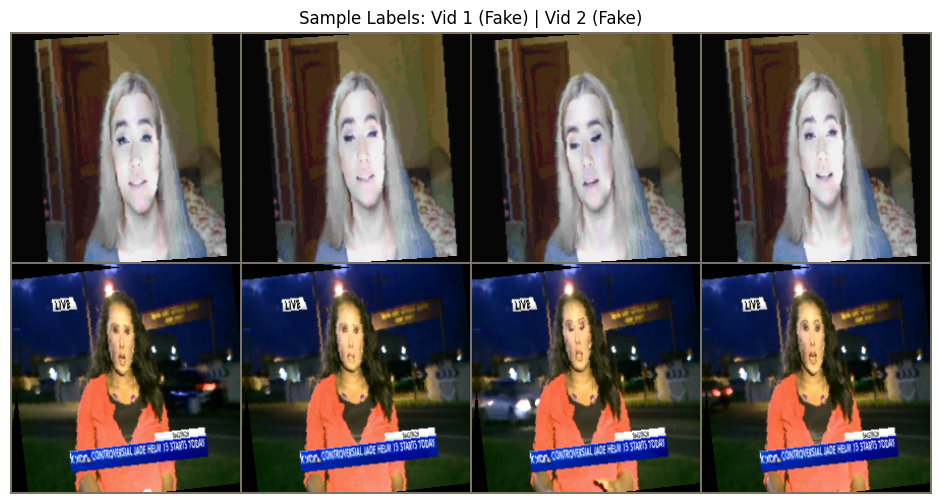

In [3]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

# Extract 4 frames from the first video and 4 frames from the second video
video_1_frames = images[0, :4]  # Shape: [4, 3, 224, 224]
video_2_frames = images[1, :4]  # Shape: [4, 3, 224, 224]

# Combine them into a 4D tensor of 8 total images (4 per row when nrow=4)
images_to_show = torch.cat([video_1_frames, video_2_frames], dim=0)

out = make_grid(images_to_show, nrow=4)

# Unnormalize the grid tensor using ImageNet stats
mean = torch.tensor([0.485, 0.456, 0.406], device=out.device).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=out.device).view(3, 1, 1)
out_unnorm = torch.clamp(out * std + mean, 0.0, 1.0)

label_mapping = {0: "Real", 1: "Fake"}
label_1 = label_mapping[int(labels[0].item())]
label_2 = label_mapping[int(labels[1].item())]

# Create titles corresponding to each of the 8 frames (4 for video 1, 4 for video 2)
titles = f"Vid 1 ({label_1}) | Vid 2 ({label_2})"

# Convert the unnormalized PyTorch tensor from make_grid [C, H, W] to a NumPy array [H, W, C]
img_np = out_unnorm.permute(1, 2, 0).cpu().numpy()

# Use matplotlib directly to avoid OpenCV argument conflicts
plt.figure(figsize=(12, 6))
plt.imshow(img_np)
plt.title(f"Sample Labels: {titles}")
plt.axis("off")
plt.show()

In [4]:
import torch.nn as nn
from torchvision.models import efficientnet_b1, EfficientNet_B1_Weights

class FFPPDeepfakeDetector(nn.Module):
    def __init__(self, lstm_hidden_size=512, num_layers=2, dropout=0.4):
        super(FFPPDeepfakeDetector, self).__init__()
        
        # Spatial Feature Extractor
        weights = EfficientNet_B1_Weights.DEFAULT
        base_model = efficientnet_b1(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-1])
        self.dropout_cnn = nn.Dropout(p=dropout)
        self.flatten = nn.Flatten()
        self.feature_dim = 1280
        
        # Temporal Sequence Network
        self.lstm = nn.LSTM(
            input_size=self.feature_dim,
            hidden_size=lstm_hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        # Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        batch_size, seq_len, c, h, w = x.shape
        x = x.view(batch_size * seq_len, c, h, w)
        
        features = self.feature_extractor(x)
        features = self.flatten(features)
        features = self.dropout_cnn(features)
        
        features = features.view(batch_size, seq_len, self.feature_dim)
        lstm_out, _ = self.lstm(features)
        
        last_timestep_features = torch.mean(lstm_out, dim=1)
        out = self.classifier(last_timestep_features)
        return out.squeeze(1)

model = FFPPDeepfakeDetector(dropout=CONFIG["dropout"]).to(CONFIG["device"])
print("Model initialized successfully and moved to device.")

Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 236MB/s]


Model initialized successfully and moved to device.


In [5]:
from sklearn.metrics import roc_auc_score, accuracy_score
from tqdm.notebook import tqdm

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=1e-3)

scaler = torch.amp.GradScaler('cuda')

val_loss_lowest = None

def train_epoch(model, dataloader, criterion, optimizer, scaler, device):
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    loader = tqdm(dataloader, desc="Training", leave=False)
    
    for videos, labels in loader:
        videos = videos.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            logits = model(videos)
            loss = criterion(logits, labels)
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item() * videos.size(0)
        preds = torch.sigmoid(logits).detach().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())
        
    epoch_loss = total_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_labels, (np.array(all_preds) >= 0.5).astype(int))
    return epoch_loss, epoch_acc


def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    loader = tqdm(dataloader, desc="Evaluating", leave=False)
    
    with torch.no_grad():
        for videos, labels in loader:
            videos = videos.to(device)
            labels = labels.to(device)
            
            with torch.amp.autocast('cuda'):
                logits = model(videos)
                loss = criterion(logits, labels)
            
            total_loss += loss.item() * videos.size(0)
            preds = torch.sigmoid(logits).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())
            
    val_loss = total_loss / len(dataloader.dataset)
    preds_binary = (np.array(all_preds) >= 0.5).astype(int)
    val_acc = accuracy_score(all_labels, preds_binary)
    
    try:
        val_roc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        val_roc = 0.0 # Catch edge case if batch only has single class representation
        
    return val_loss, val_acc, val_roc


# --- EXECUTE TRAINING PIPELINE ---
print("Starting training pipeline...")
for epoch in range(CONFIG["num_epochs"]):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, scaler, CONFIG["device"])
    val_loss, val_acc, val_roc = evaluate(model, val_loader, criterion, CONFIG["device"])

    if val_loss_lowest == None or val_loss < val_loss_lowest:
        val_loss_lowest = val_loss
        save_path = "/kaggle/working/ffpp_deepfake_detector.pth"
    
        # Save the state dictionary configuration weights 
        torch.save(model.state_dict(), save_path)
        print(f"New lowest loss reached: {val_loss}\nModel weights saved successfully to: {save_path}")
    
    print(f"Epoch [{epoch+1}/{CONFIG['num_epochs']}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f} - Val ROC-AUC: {val_roc:.4f}")

if val_loss_lowest is not None:
    print(f"\nLoading best model weights from {save_path} (Val Loss: {val_loss_lowest:.4f})...")
    model.load_state_dict(torch.load(save_path, map_location=CONFIG["device"]))

print("Training complete!")

Starting training pipeline...


Training:   0%|          | 0/525 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

New lowest loss reached: 0.6370525622367859
Model weights saved successfully to: /kaggle/working/ffpp_deepfake_detector.pth
Epoch [1/5] | Train Loss: 0.4525 - Train Acc: 0.8329 | Val Loss: 0.6371 - Val Acc: 0.5000 - Val ROC-AUC: 0.7665


Training:   0%|          | 0/525 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [4/5] | Train Loss: 0.0789 - Train Acc: 0.9724 | Val Loss: 0.6438 - Val Acc: 0.8400 - Val ROC-AUC: 0.9290


Training:   0%|          | 0/525 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [5/5] | Train Loss: 0.0557 - Train Acc: 0.9814 | Val Loss: 0.8823 - Val Acc: 0.8067 - Val ROC-AUC: 0.9284

Loading best model weights from /kaggle/working/ffpp_deepfake_detector.pth (Val Loss: 0.4047)...
Training complete!


  Optimal Threshold : 0.5654

  accuracy          : 0.7900
  precision_macro   : 0.7903
  recall_macro      : 0.7900
  f1_macro          : 0.7899
  precision_fake    : 0.7806
  recall_fake       : 0.8067
  f1_fake           : 0.7934
  roc_auc           : 0.8703

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        Real       0.80      0.77      0.79       150
        Fake       0.78      0.81      0.79       150

    accuracy                           0.79       300
   macro avg       0.79      0.79      0.79       300
weighted avg       0.79      0.79      0.79       300



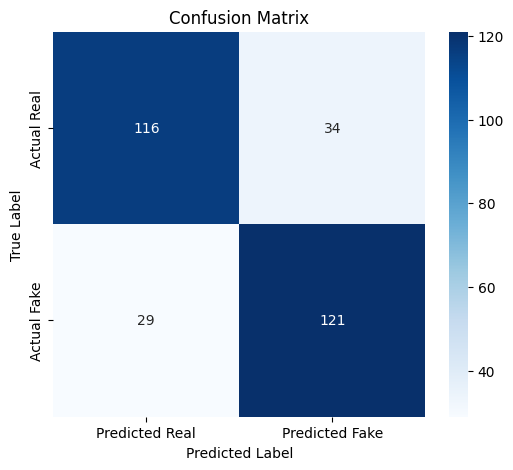

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, precision_recall_curve, f1_score,
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_auc_score,
)

def generate_final_report(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for videos, labels in dataloader:
            videos = videos.to(device)
            with torch.amp.autocast('cuda'):
                logits = model(videos)
            preds = torch.sigmoid(logits).cpu().numpy()
            
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
            
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels).astype(int)

    # Calculate optimal threshold using Youden's J statistic (0: Real, 1: Fake)
    fpr, tpr, thresholds = roc_curve(all_labels, all_preds)
    j_scores = tpr - fpr
    optimal_idx = np.argmax(j_scores)
    optimal_threshold = thresholds[optimal_idx]

    print(f"  Optimal Threshold : {optimal_threshold:.4f}\n")

    binary_preds = (all_preds >= optimal_threshold).astype(int)
    
    # 1. Print Classification Metrics
    metrics = {
        "accuracy":        accuracy_score(all_labels, binary_preds),
        "precision_macro": precision_score(all_labels, binary_preds, average="macro", zero_division=0),
        "recall_macro":    recall_score(all_labels, binary_preds, average="macro", zero_division=0),
        "f1_macro":        f1_score(all_labels, binary_preds, average="macro", zero_division=0),
        "precision_fake":  precision_score(all_labels, binary_preds, pos_label=1, zero_division=0),
        "recall_fake":     recall_score(all_labels, binary_preds, pos_label=1, zero_division=0),
        "f1_fake":         f1_score(all_labels, binary_preds, pos_label=1, zero_division=0),
        "roc_auc":         roc_auc_score(all_labels, all_preds),   # AUC is threshold-independent, unchanged
    }
    for k, v in metrics.items():
        print(f"  {k:<18}: {v:.4f}")
    
    # 2. Print Classification Report
    print("\n=== CLASSIFICATION REPORT ===")
    print(classification_report(all_labels, binary_preds, target_names=['Real', 'Fake']))
    
    # 3. Compute and Plot Confusion Matrix
    cm = confusion_matrix(all_labels, binary_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Predicted Real', 'Predicted Fake'],
                yticklabels=['Actual Real', 'Actual Fake'])
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Run evaluation report
generate_final_report(model, test_loader, CONFIG["device"])

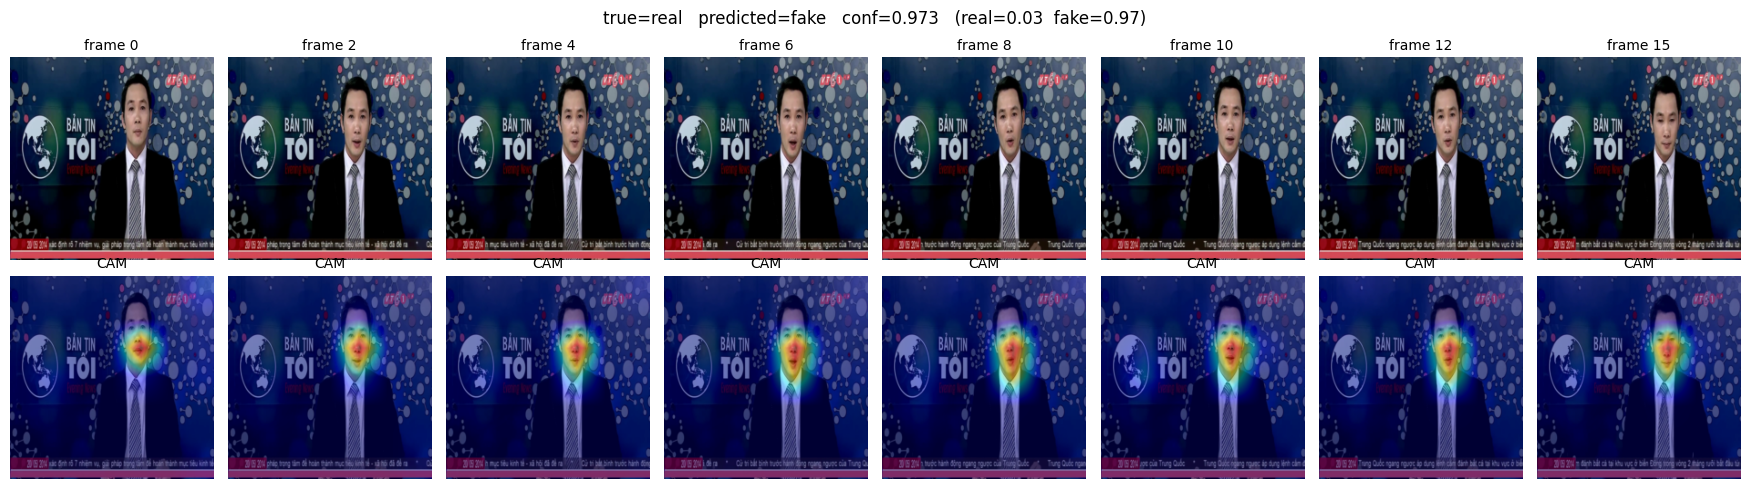

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

class VideoGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Register modern hooks (prevents PyTorch deprecation warnings)
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output.detach()
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
        
    def generate_heatmaps_all_frames(self, video_tensor):
        """
        Generates GradCAM heatmaps for ALL frames in the input video tensor sequence.
        video_tensor shape: (1, seq_len, 3, 224, 224)
        Returns: logits, probability score, and heatmaps numpy array of shape (seq_len, H, W)
        """
        was_training = self.model.training
        
        # Force model to train mode during backward pass so cuDNN RNN handles backward computation
        self.model.train()
        
        # Forward pass
        logits = self.model(video_tensor)
        prob = torch.sigmoid(logits).item()
        
        # Backward pass for gradients
        self.model.zero_grad()
        logits.backward()
        
        # self.gradients and self.activations have shape: (seq_len, C, H, W)
        grads = self.gradients
        acts = self.activations
        
        # Global average pooling of gradients per frame
        weights = torch.mean(grads, dim=(2, 3), keepdim=True) # Shape: (seq_len, C, 1, 1)
        
        # Weighted combination of activation maps
        cams = torch.sum(weights * acts, dim=1) # Shape: (seq_len, H, W)
        cams = F.relu(cams) # Isolated features positively contributing to score

        _, seq_len_dim, _, img_h, img_w = video_tensor.shape
        cams_resized = F.interpolate(
            cams.unsqueeze(1), 
            size=(img_h, img_w), 
            mode='bilinear', 
            align_corners=False
        ).squeeze(1) # Shape: (seq_len, img_h, img_w)
        
        # Normalize each frame's heatmap individually
        heatmaps = []
        for i in range(cams.size(0)):
            cam = cams_resized[i]
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-7)
            heatmaps.append(cam.cpu().numpy())

        if not was_training:
            self.model.eval()
            
        return logits, prob, np.array(heatmaps)


def visualize_gradcam_sequence(model, dataset, sample_idx=0, num_frames_to_display=8):
    # Target layer: EfficientNet-B1's final sequential block before pooling
    target_layer = model.feature_extractor[0][-1] 
    grad_cam = VideoGradCAM(model, target_layer)
    
    # Fetch sample data 
    video_tensor, true_label_idx = dataset[-1]
    true_label = "fake" if int(true_label_idx.item()) == 1 else "real"
    
    # Add batch dimension and enable gradients
    video_tensor_input = video_tensor.unsqueeze(0).to(CONFIG["device"])
    video_tensor_input.requires_grad = True
    
    # Generate heatmaps for all frames
    _, fake_prob, heatmaps = grad_cam.generate_heatmaps_all_frames(video_tensor_input)
    
    real_prob = 1.0 - fake_prob
    pred_label = "fake" if fake_prob >= 0.5 else "real"
    conf = fake_prob if pred_label == "fake" else real_prob
    
    total_seq_len = video_tensor.size(0)
    
    # Select evenly spaced frame indices across the sequence
    frame_indices = np.linspace(0, total_seq_len - 1, num_frames_to_display, dtype=int)
    
    # De-normalize image constants
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    # Setup Figure Layout (2 Rows x N Columns)
    fig, axes = plt.subplots(2, num_frames_to_display, figsize=(2.2 * num_frames_to_display, 5))
    
    # Set top title matching the requested format
    fig.suptitle(
        f"true={true_label}   predicted={pred_label}   conf={conf:.3f}   (real={real_prob:.2f}  fake={fake_prob:.2f})",
        fontsize=12, y=0.98
    )

    for i, f_idx in enumerate(frame_indices):
        # 1. Reconstruct source RGB frame
        src_frame = video_tensor[f_idx].detach().cpu().numpy().transpose(1, 2, 0)
        src_frame = std * src_frame + mean
        src_frame = np.clip(src_frame, 0, 1)
        src_frame_uint8 = (src_frame * 255).astype(np.uint8)
        
        # 2. Resize heatmap and create overlay
        heatmap_resized = cv2.resize(heatmaps[f_idx], (CONFIG["img_size"], CONFIG["img_size"]))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
        
        overlay = cv2.addWeighted(src_frame_uint8, 0.6, heatmap_color, 0.4, 0)
        
        # --- Top Row: Original Frame with slight darkness/blend ---
        axes[0, i].imshow(src_frame)
        axes[0, i].set_title(f"frame {f_idx}", fontsize=10)
        axes[0, i].axis('off')
        
        # --- Bottom Row: CAM Overlay ---
        axes[1, i].imshow(overlay)
        axes[1, i].set_title("CAM", fontsize=10)
        axes[1, i].axis('off')
        
    plt.tight_layout()
    plt.show()

# Run the updated multi-frame visualization on validation sample 0
visualize_gradcam_sequence(model, test_dataset, sample_idx=0, num_frames_to_display=8)

Running Deletion Faithfulness Analysis on 50 test videos...


Evaluating Faithfulness:   0%|          | 0/50 [00:00<?, ?it/s]


--- Faithfulness Results ---
Mean AUC_del across 50 videos: 0.4579


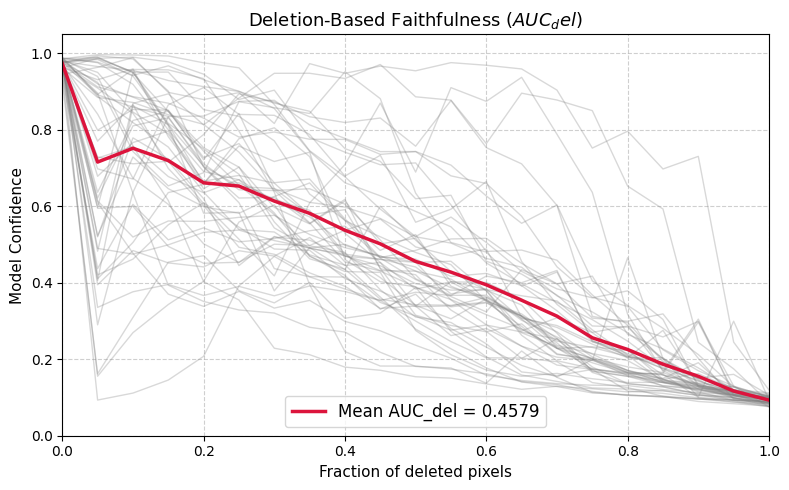

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc
from tqdm.notebook import tqdm

def evaluate_dataset_deletion_faithfulness(model, dataset, target_layer, num_samples=20, steps=20, baseline=0.0):
    """
    Computes the Deletion-Based Faithfulness (AUC_del) across a subset of a video dataset.
    Optimized with vectorized tensor indexing to prevent RAM spikes and freezing.
    """
    model.eval()
    device = CONFIG["device"]
    grad_cam = VideoGradCAM(model, target_layer)
    
    num_samples = min(num_samples, len(dataset))
    sample_indices = np.linspace(0, len(dataset) - 1, num_samples, dtype=int)
    
    all_auc_values = []
    all_curves = []
    
    print(f"Running Deletion Faithfulness Analysis on {num_samples} test videos...")
    
    for idx in tqdm(sample_indices, desc="Evaluating Faithfulness"):
        video_tensor, label = dataset[idx]
        
        # Prepare input video tensor shape: (1, seq_len, C, H, W)
        video_tensor_input = video_tensor.unsqueeze(0).to(device)
        
        target_class_idx = int(label.item())
        
        # 1. Generate spatio-temporal heatmap of shape (seq_len, H, W)
        try:
            logits, prob, heatmap = grad_cam.generate_heatmaps_all_frames(video_tensor_input)
        except Exception as e:
            continue # Skip edge cases
            
        # Get baseline confidence (0% deleted)
        orig_conf = prob
        
        # Flatten spatio-temporal heatmap into a 1D array of voxels
        flat_heatmap = heatmap.flatten()
        sorted_indices = np.argsort(flat_heatmap)[::-1] # Highest importance first
        
        total_voxels = len(flat_heatmap)
        step_size = max(1, total_voxels // steps)
        
        confidences = [orig_conf]
        percentages = [0.0]
        
        # Pre-calculate (t, h, w) coordinate arrays once for all voxels
        t_all, h_all, w_all = np.unravel_index(sorted_indices, heatmap.shape)
        
        # Convert coordinate arrays to PyTorch tensors on the correct device for instant indexing
        t_tensor = torch.tensor(t_all, dtype=torch.long, device=device)
        h_tensor = torch.tensor(h_all, dtype=torch.long, device=device)
        w_tensor = torch.tensor(w_all, dtype=torch.long, device=device)
        
        # Clone video tensor to perform iterative deletion
        modified_video = video_tensor_input.clone()
        
        # 2. Progressively mask out top-ranked voxels using vectorized slicing
        for step in range(1, steps + 1):
            num_to_delete = min(step * step_size, total_voxels)
            
            if num_to_delete > 0:
                # Slice the pre-computed coordinate tensors up to the current step
                t_sub = t_tensor[:num_to_delete]
                h_sub = h_tensor[:num_to_delete]
                w_sub = w_tensor[:num_to_delete]
                
                # --- VECTORIZED ASSIGNMENT (Instant, zero Python loop overhead) ---
                modified_video[0, t_sub, :, h_sub, w_sub] = baseline
                
            # 3. Track model confidence on the modified video
            with torch.no_grad():
                mod_logits = model(modified_video)
                mod_prob = torch.sigmoid(mod_logits).item()
                mod_conf = mod_prob # Model confidence is how confident it is that the video is fake
                
            confidences.append(mod_conf)
            percentages.append(num_to_delete / total_voxels)
            
        # 4. Compute Area Under the Curve for this video
        video_auc = auc(percentages, confidences)
        all_auc_values.append(video_auc)
        all_curves.append((percentages, confidences, video_auc))
        
        # Clear CUDA cache between samples to keep memory clean
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        
    mean_auc = np.mean(all_auc_values) if all_auc_values else 0.0
    print(f"\n--- Faithfulness Results ---")
    print(f"Mean AUC_del across {len(all_auc_values)} videos: {mean_auc:.4f}")
    
    return mean_auc, all_curves

# --- Execute Evaluation and Plot Average Curve ---
target_layer = model.feature_extractor[0][-1]
mean_auc_score, curves_data = evaluate_dataset_deletion_faithfulness(
    model=model,
    dataset=test_dataset,
    target_layer=target_layer,
    num_samples=CONFIG["faithfulness_num_samples"],  # Adjust based on how many videos you want to test (e.g., 20 or 50)
    steps=20
)

# Plotting the aggregate curve behavior
plt.figure(figsize=(8, 5))
for p_list, c_list, _ in curves_data:
    plt.plot(p_list, c_list, color='gray', alpha=0.3, linewidth=1) # Individual video curves

# Plot mean trajectory trend
if curves_data:
    mean_p = curves_data[0][0]
    mean_c = np.mean([c for _, c, _ in curves_data], axis=0)
    plt.plot(mean_p, mean_c, color='crimson', linewidth=2.5, label=f'Mean AUC_del = {mean_auc_score:.4f}')

plt.title('Deletion-Based Faithfulness ($AUC_del$)', fontsize=13)
plt.xlabel('Fraction of deleted pixels', fontsize=11)
plt.ylabel('Model Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0, 1.05)
plt.xlim(0, 1.0)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

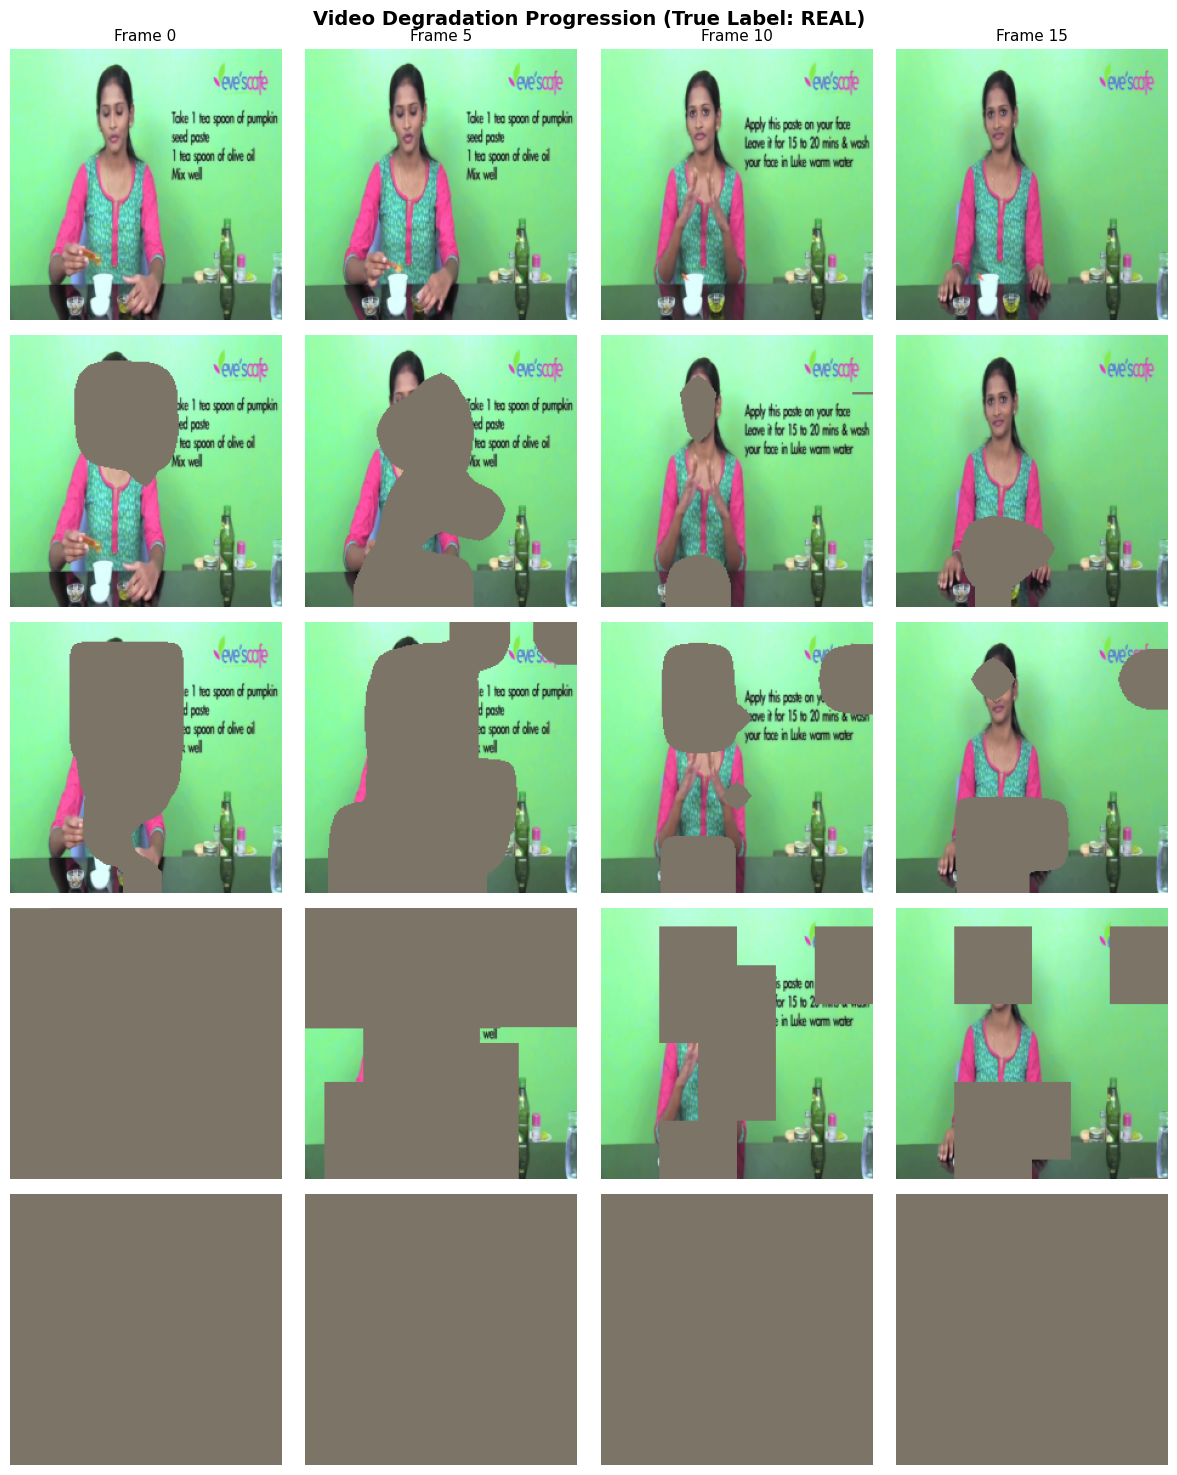

In [9]:
import matplotlib.pyplot as plt

def visualize_video_degradation_grid(model, dataset, target_layer, sample_idx=0, deletion_fractions=[0.0, 0.15, 0.35, 0.60, 1.0], num_display_frames=4):
    model.eval()
    device = CONFIG["device"]
    grad_cam = VideoGradCAM(model, target_layer)
    
    # 1. Fetch sample video
    video_tensor, label = dataset[sample_idx]
    video_tensor_input = video_tensor.unsqueeze(0).to(device)
    
    target_class_idx = int(label.item())
    true_label = "fake" if target_class_idx == 1 else "real"
    
    # 2. Generate full-resolution GradCAM heatmap across all frames
    try:
        logits, prob, heatmap = grad_cam.generate_heatmaps_all_frames(video_tensor_input)
    except Exception as e:
        print(f"Error generating heatmap: {e}")
        return
        
    flat_heatmap = heatmap.flatten()
    sorted_indices = np.argsort(flat_heatmap)[::-1] # Highest importance first
    total_voxels = len(flat_heatmap)
    
    total_seq_len = video_tensor.size(0)
    frame_indices = np.linspace(0, total_seq_len - 1, num_display_frames, dtype=int)
    
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    # Pure black mapping in normalized space shape: (3,)
    black_baseline_norm = torch.tensor(-mean / std, dtype=video_tensor.dtype, device=device)
    
    fig, axes = plt.subplots(len(deletion_fractions), num_display_frames, figsize=(3 * num_display_frames, 3 * len(deletion_fractions)))
    fig.suptitle(f"Video Degradation Progression (True Label: {true_label.upper()})", fontsize=14, fontweight='bold', y=0.98)
    
    for row_idx, frac in enumerate(deletion_fractions):
        modified_video = video_tensor_input.clone()
        num_to_delete = int(frac * total_voxels)
        
        if num_to_delete > 0:
            voxels_to_mask = sorted_indices[:num_to_delete]
            t_idxs, h_idxs, w_idxs = np.unravel_index(voxels_to_mask, heatmap.shape)
            
            # --- VECTORIZED MASKING ---
            # Directly index all target voxels across all 3 channels at once
            modified_video[0, t_idxs, :, h_idxs, w_idxs] = 0
                    
        with torch.no_grad():
            mod_logits = model(modified_video)
            mod_prob = torch.sigmoid(mod_logits).item()
            mod_conf = mod_prob if target_class_idx == 1 else (1.0 - mod_prob)
            
        for col_idx, f_idx in enumerate(frame_indices):
            ax = axes[row_idx, col_idx] if len(deletion_fractions) > 1 else axes[col_idx]
            
            frame_np = modified_video[0, f_idx].detach().cpu().numpy().transpose(1, 2, 0)
            frame_np = std * frame_np + mean
            frame_np = np.clip(frame_np, 0, 1)
            
            ax.imshow(frame_np)
            ax.axis('off')
            
            if col_idx == 0:
                ax.set_ylabel(f"{int(frac * 100)}% Deleted\n(Conf: {mod_conf:.3f})", fontsize=10, fontweight='bold')
                
            if row_idx == 0:
                ax.set_title(f"Frame {f_idx}", fontsize=11)
                
    plt.tight_layout()
    plt.show()

# --- Run ---
target_layer = model.feature_extractor[0][-1]
visualize_video_degradation_grid(
    model=model,
    dataset=test_dataset,
    target_layer=target_layer,
    sample_idx=0, 
    deletion_fractions=[0.0, 0.15, 0.35, 0.60, 1.0], 
    num_display_frames=4
)